## About the dataset

We use the Bank Marketing dataset. It comes from a bank that ran a phone campaign to sell a
term deposit (a type of savings product). Each row is one customer who was called, and the
task is to predict whether the customer said yes and subscribed.

The dataset has many categorical columns, which is exactly what we want for this lesson:

- job, marital, education
- default, housing, loan
- contact, month, day_of_week
- poutcome (the result of a previous campaign)

It also has some number columns such as age and some economic indicators. The column we try
to predict is called y, and it is either "no" or "yes".

The next cell downloads the file from a public mirror on GitHub, so you do not need to
download anything by hand.


# Ensemble Learning on Tabular Data with Categorical Columns

In an earlier notebook we used ensemble models on tweets, where the input was text. In this
notebook we work with a different and very common kind of data: a table with rows and columns,
where many of the columns are categories (words like "married" or "student") instead of numbers.

Our goal is the same idea as before. We build five models and compare them:

1. Logistic Regression (this is our baseline model)
2. Random Forest
3. XGBoost
4. LightGBM
5. CatBoost

Models 2 to 5 are ensemble models. They build many decision trees and let the trees work
together to make a stronger and more stable prediction.

This notebook adds two new ideas on top of the basic version:

- Not all models treat categorical columns the same way. Logistic Regression and Random Forest
  need plain numbers, so we turn the categories into numbers with one-hot encoding. XGBoost,
  LightGBM, and CatBoost can handle categorical columns on their own, so we give them the raw
  columns and let each model do the smart thing. To support both styles we keep two versions
  of the training data.
- We also do a little hyperparameter tuning for every model. Each model has some settings
  (called hyperparameters) that change how it learns. We use a tool called GridSearchCV to try
  a few settings and keep the best ones.
- Finally, and importantly, we do not judge the models by accuracy alone. Our data is
  imbalanced (most customers say no), so a model that always guesses no would already look
  about 89 percent accurate while being useless. Instead we look at precision, recall, F1,
  ROC-AUC, and PR-AUC, which tell us how well the model finds the rarer yes customers.


## Step 1: Install the required libraries

Run this cell only once. Notice that this time we do not need BERT or torch, because our
data is already a table. We only need the models and the usual data tools.


In [10]:
!pip install scikit-learn xgboost lightgbm catboost pandas numpy matplotlib


## Step 2: Import the libraries

Here we bring in everything we need. As in the earlier notebook, we set a couple of safety
settings at the top so the tree libraries do not clash on some computers (especially Mac).


In [11]:
# safety settings for OpenMP, so the tree libraries stay stable on all computers
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

# hide a few harmless version warnings so the output stays clean
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# tools to prepare the data, tune the models, and check the results
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder

# the metrics we will use. accuracy alone is not enough for imbalanced data,
# so we also bring in precision, recall, f1, the two area-under-curve scores,
# the confusion matrix, and the curve helpers for plotting.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

# the five models we will train
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


## Step 3: Download the data file

This cell downloads the dataset and saves it next to this notebook. We only download it if
it is not already there, so running this cell again is safe and fast.


In [12]:
import urllib.request

data_url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-full.csv"

if not os.path.exists("bank_marketing.csv"):
    print("Downloading the data file...")
    urllib.request.urlretrieve(data_url, "bank_marketing.csv")
else:
    print("Data file already exists.")

print("Done. The data file is ready.")


Data file already exists.
Done. The data file is ready.


## Step 4: Load the data

This file uses a semicolon (;) to separate the columns instead of a comma, so we tell pandas
about that with the sep option.


In [13]:
data = pd.read_csv("bank_marketing.csv", sep=";")

print("Rows and columns:", data.shape)


Rows and columns: (41188, 21)


In [14]:
# look at the first few rows to understand the data
data.head()


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### What each column means

Before we model anything, it helps to know what every column actually records. The dataset has
21 columns. They fall into a few natural groups.

Details about the customer:

- age: the customer's age in years (a number).
- job: the type of job, for example admin., blue-collar, technician, retired, student.
- marital: marital status: married, single, or divorced (divorced also covers widowed).
- education: the highest education level, for example high.school, university.degree,
  basic.9y, professional.course.
- default: does the customer have credit in default (unpaid)? Values are no, yes, or unknown.
- housing: does the customer have a housing loan? Values are no, yes, or unknown.
- loan: does the customer have a personal loan? Values are no, yes, or unknown.

Details about the last phone call in this campaign:

- contact: how the customer was contacted: cellular (mobile) or telephone (landline).
- month: the month of the last contact, for example may, jun, jul.
- day_of_week: the weekday of the last contact: mon, tue, wed, thu, or fri.
- duration: how long the last call lasted, in seconds. This one is special. We only know it
  after the call is over, and a very short call almost always means no. Using it would be
  unfair (a kind of cheating), so we drop this column later.

Details about past contact with the customer:

- campaign: how many times this customer was contacted during the current campaign.
- pdays: how many days have passed since the customer was last contacted in a previous
  campaign. A value of 999 is a special code that means the customer was never contacted before.
- previous: how many times this customer was contacted before the current campaign.
- poutcome: the result of the previous campaign for this customer: success, failure, or
  nonexistent (nonexistent means there was no previous campaign).

The general economic mood at the time of the call (these are the same for many rows, because
they describe the wider economy, not the single customer):

- emp.var.rate: the employment variation rate, a measure of how employment is changing.
- cons.price.idx: the consumer price index, a measure of prices (linked to inflation).
- cons.conf.idx: the consumer confidence index, how positive people feel about the economy.
- euribor3m: the Euribor 3 month interest rate.
- nr.employed: the number of people employed in the country (in thousands).

The column we want to predict:

- y: did the customer subscribe to the term deposit? This is our target, and it is either no
  or yes.


## Step 5: Explore the data

Let us first see how many customers said yes and how many said no.


In [15]:
# count how many customers subscribed (yes) and how many did not (no)
target_counts = data["y"].value_counts()
print(target_counts)


y
no     36548
yes     4640
Name: count, dtype: int64


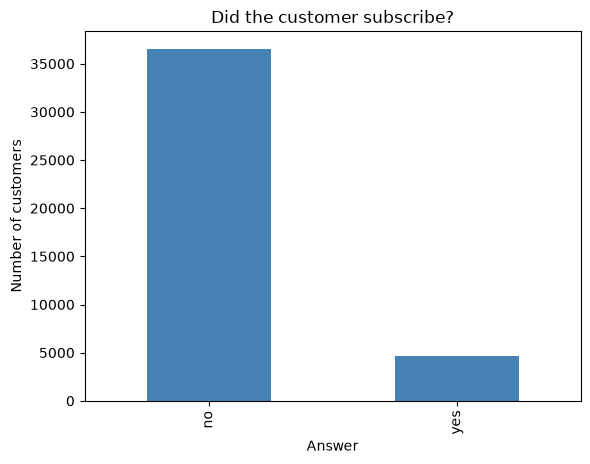

In [16]:
# draw a simple bar chart of the answers
target_counts.plot(kind="bar", color="steelblue")
plt.title("Did the customer subscribe?")
plt.xlabel("Answer")
plt.ylabel("Number of customers")
plt.show()


Notice that most customers said no. This is called an imbalanced dataset. It matters
because a lazy model that always guesses no would already look about 89 percent correct. So
when we read the accuracy later, we should keep this in mind and also look at the detailed
report, which shows how well the model finds the rarer yes cases.


In [17]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [18]:
# let us also look at the categorical columns and how many different values each one has
categorical_columns = data.select_dtypes(include="object").columns.tolist()

# the last one is the answer column y, so we remove it from this list
categorical_columns.remove("y")

for column in categorical_columns:
    print(column, "->", data[column].nunique(), "different values")


job -> 12 different values
marital -> 4 different values
education -> 8 different values
default -> 3 different values
housing -> 3 different values
loan -> 3 different values
contact -> 2 different values
month -> 10 different values
day_of_week -> 5 different values
poutcome -> 3 different values


## Step 6: Prepare two versions of the features

This is the main new idea of this notebook. Different models like their input in different
shapes, so we prepare two versions of the same data.

First we drop a column called duration. It records how long the phone call lasted. The problem
is that we only know this after the call is over, so using it to predict the outcome would be
unfair. Dropping it gives us an honest model.

Then we build the two versions:

- Version A, numbers only. Logistic Regression and Random Forest can only work with numbers.
  For them we use one-hot encoding, which turns each category into simple yes or no number
  columns. The pandas function get_dummies does this in one line.

- Version B, categories kept. XGBoost, LightGBM, and CatBoost are able to work with categorical
  columns directly, in their own smart way. For them we keep the original columns and only tell
  pandas that these columns are of type "category". We do not one-hot encode them.


In [19]:
# drop the duration column to avoid unfair predictions
data = data.drop(columns=["duration"])

# split into input columns (X) and the answer we want to predict
X_raw = data.drop(columns=["y"])
y_raw = data["y"]

# Version A: one-hot encoded numbers (for Logistic Regression and Random Forest)
X_encoded = pd.get_dummies(X_raw)

# Version B: keep the categorical columns, just mark them as the "category" type
# (for XGBoost, LightGBM, and CatBoost, which handle categories natively)
X_native = X_raw.copy()
for column in categorical_columns:
    X_native[column] = X_native[column].astype("category")

print("Version A (one-hot) number of columns:", X_encoded.shape[1])
print("Version B (categories kept) number of columns:", X_native.shape[1])


Version A (one-hot) number of columns: 62
Version B (categories kept) number of columns: 19


## Step 7: Prepare the labels

The answer column y contains the words no and yes. We turn these into numbers using a
LabelEncoder, so that no becomes 0 and yes becomes 1.


In [20]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

print("Label mapping:")
for number, name in enumerate(label_encoder.classes_):
    print(number, "->", name)


Label mapping:
0 -> no
1 -> yes


## Step 8: Split into training and testing sets

We keep 80 percent of the rows to train the models and 20 percent to test them. We split both
versions of the data. Because we use the same random_state and stratify for both splits, the
rows line up: the same customers go into training in both versions, and the same customers go
into testing. So the labels y_train and y_test are the same for both versions.


In [21]:
# split Version A (one-hot) and also get the shared labels
X_enc_train, X_enc_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# split Version B (categories kept) the same way
X_nat_train, X_nat_test, _, _ = train_test_split(
    X_native, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_enc_train))
print("Testing rows:", len(X_enc_test))


Training rows: 32950
Testing rows: 8238


## Step 9: A helper to tune and measure each model

We write one small function that does the whole job for a model:

1. It uses GridSearchCV to try a few settings and pick the best ones. Because the data is
   imbalanced, we tell GridSearchCV to score the settings using PR-AUC (average precision)
   instead of accuracy. PR-AUC focuses on how well the model finds the rare yes customers, so
   it picks settings that are good for our real goal.
2. It uses the best model to make two kinds of predictions on the test rows: the yes or no
   labels, and the probability of yes. Some metrics need the labels and some need the
   probability.
3. It measures many metrics and saves them, so we can compare all the models at the end.

The metrics we measure, and why each one matters here:

- accuracy: the share of all predictions that are correct. Easy to read, but misleading on
  imbalanced data, so we keep it only as a rough check.
- precision (for yes): out of the customers the model flagged as yes, how many really said yes.
  High precision means we waste few calls.
- recall (for yes): out of all the customers who really said yes, how many the model found.
  High recall means we miss few real subscribers.
- f1 (for yes): a single number that balances precision and recall.
- roc_auc: how well the model ranks a random yes customer above a random no customer. It is
  threshold free and easy to compare, but it can look high on imbalanced data.
- pr_auc: the area under the precision-recall curve. This is the most honest headline metric
  here, because it looks only at the rare yes class.

The function takes the training and testing data as inputs, so we can pass Version A or
Version B depending on the model. It also takes an optional fit_params, which we use only for
CatBoost to tell it which columns are categorical.


In [22]:
# a dictionary to keep the metrics of every model
results = {}

# a dictionary to keep the predicted yes-probabilities, used later for the curves
model_scores = {}

def tune_and_check(model, param_grid, model_name, X_tr, X_te, fit_params=None):
    if fit_params is None:
        fit_params = {}

    # try every combination of settings and keep the best one (3-fold cross validation)
    # we score by PR-AUC (average_precision) because the data is imbalanced
    grid = GridSearchCV(model, param_grid, cv=3, scoring="average_precision", n_jobs=1)
    grid.fit(X_tr, y_train, **fit_params)

    best_model = grid.best_estimator_

    # yes or no labels, and the probability of yes
    predictions = best_model.predict(X_te)
    probabilities = best_model.predict_proba(X_te)[:, 1]

    # measure all the metrics (yes is the class we care about, which is label 1)
    metrics = {
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions),
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "pr_auc": average_precision_score(y_test, probabilities),
    }

    # print a clear summary for this model
    print(model_name, "best settings:", grid.best_params_)
    for metric_name in metrics:
        print("   ", metric_name, ":", round(metrics[metric_name], 4))
    print()
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(confusion_matrix(y_test, predictions))
    print()
    print(classification_report(y_test, predictions, target_names=label_encoder.classes_))

    # save the metrics and the probabilities for the comparison later
    results[model_name] = metrics
    model_scores[model_name] = probabilities
    return best_model


## Model 1: Logistic Regression (the baseline)

We start simple. Logistic Regression draws a straight boundary between the two groups. It
needs plain numbers, so we give it Version A (the one-hot encoded data). The setting we tune
is C, which controls how strongly the model avoids overfitting.


In [23]:
tune_and_check(
    LogisticRegression(max_iter=1000),
    {"C": [0.1, 1.0, 10.0]},
    "Logistic Regression",
    X_enc_train, X_enc_test
)


Logistic Regression best settings: {'C': 1.0}
    accuracy : 0.9012
    precision : 0.7021
    recall : 0.2134
    f1 : 0.3273
    roc_auc : 0.7984
    pr_auc : 0.4631

Confusion matrix (rows = actual, columns = predicted):
[[7226   84]
 [ 730  198]]

              precision    recall  f1-score   support

          no       0.91      0.99      0.95      7310
         yes       0.70      0.21      0.33       928

    accuracy                           0.90      8238
   macro avg       0.81      0.60      0.64      8238
weighted avg       0.89      0.90      0.88      8238



,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

## Model 2: Random Forest

Random Forest is our first ensemble model. It builds many decision trees, lets each tree vote,
and takes the majority vote. The sklearn version needs numbers, so it also uses Version A. We
tune the number of trees and how deep each tree can grow.


In [24]:
tune_and_check(
    RandomForestClassifier(random_state=42),
    {"n_estimators": [100, 200], "max_depth": [10, 20]},
    "Random Forest",
    X_enc_train, X_enc_test
)


Random Forest best settings: {'max_depth': 10, 'n_estimators': 200}
    accuracy : 0.902
    precision : 0.7108
    recall : 0.2198
    f1 : 0.3358
    roc_auc : 0.8114
    pr_auc : 0.4849

Confusion matrix (rows = actual, columns = predicted):
[[7227   83]
 [ 724  204]]

              precision    recall  f1-score   support

          no       0.91      0.99      0.95      7310
         yes       0.71      0.22      0.34       928

    accuracy                           0.90      8238
   macro avg       0.81      0.60      0.64      8238
weighted avg       0.89      0.90      0.88      8238



,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [ ]:
# precision - recall tradeoff
# if threshold is 0.0 => all +ve predictions => precision = 0.0, recall = 1.0

# if threshold is 1.0 => all -ve predictions => precision = 0.0, recall = 0.0

## Model 3: XGBoost (handles categories natively)

XGBoost is a boosting model. Boosting builds trees one after another, and each new tree tries
to fix the mistakes of the trees before it.

XGBoost can work with categorical columns on its own. We turn this on with
enable_categorical=True and give it Version B (the raw columns marked as "category"). So there
is no one-hot encoding here. We tune the depth of the trees and the learning rate.


In [25]:
tune_and_check(
    XGBClassifier(random_state=42, eval_metric="logloss",
                  enable_categorical=True, tree_method="hist"),
    {"n_estimators": [200], "max_depth": [3, 6], "learning_rate": [0.1, 0.3]},
    "XGBoost",
    X_nat_train, X_nat_test
)


XGBoost best settings: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
    accuracy : 0.9024
    precision : 0.6782
    recall : 0.2543
    f1 : 0.3699
    roc_auc : 0.8118
    pr_auc : 0.4842

Confusion matrix (rows = actual, columns = predicted):
[[7198  112]
 [ 692  236]]

              precision    recall  f1-score   support

          no       0.91      0.98      0.95      7310
         yes       0.68      0.25      0.37       928

    accuracy                           0.90      8238
   macro avg       0.80      0.62      0.66      8238
weighted avg       0.89      0.90      0.88      8238



,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## Model 4: LightGBM (handles categories natively)

LightGBM is another boosting model, made by Microsoft. It is built to be fast and to use less
memory. It also understands categorical columns directly: when it sees columns of type
"category", it treats them as categories automatically. So we give it Version B as well. We
tune the number of trees, the number of leaves, and the learning rate.


In [26]:
tune_and_check(
    LGBMClassifier(random_state=42, verbose=-1),
    {"n_estimators": [200], "num_leaves": [31, 63], "learning_rate": [0.1]},
    "LightGBM",
    X_nat_train, X_nat_test
)


LightGBM best settings: {'learning_rate': 0.1, 'n_estimators': 200, 'num_leaves': 31}
    accuracy : 0.9035
    precision : 0.6595
    recall : 0.2963
    f1 : 0.4089
    roc_auc : 0.8048
    pr_auc : 0.4974

Confusion matrix (rows = actual, columns = predicted):
[[7168  142]
 [ 653  275]]

              precision    recall  f1-score   support

          no       0.92      0.98      0.95      7310
         yes       0.66      0.30      0.41       928

    accuracy                           0.90      8238
   macro avg       0.79      0.64      0.68      8238
weighted avg       0.89      0.90      0.89      8238



,n_estimators,200
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


## Model 5: CatBoost (handles categories natively)

CatBoost is a boosting model made by Yandex. Its name comes from the word categorical, because
it was specially designed to handle categorical columns very well. We give it Version B, and we
tell it which columns are categorical using cat_features. This is passed through fit_params in
our helper. We tune the depth of the trees and the learning rate.


In [27]:
tune_and_check(
    CatBoostClassifier(n_estimators=200, random_state=42, verbose=0),
    {"depth": [4, 6], "learning_rate": [0.1, 0.3]},
    "CatBoost",
    X_nat_train, X_nat_test,
    fit_params={"cat_features": categorical_columns}
)


CatBoost best settings: {'depth': 6, 'learning_rate': 0.1}
    accuracy : 0.9029
    precision : 0.6778
    recall : 0.2629
    f1 : 0.3789
    roc_auc : 0.8115
    pr_auc : 0.4893

Confusion matrix (rows = actual, columns = predicted):
[[7194  116]
 [ 684  244]]

              precision    recall  f1-score   support

          no       0.91      0.98      0.95      7310
         yes       0.68      0.26      0.38       928

    accuracy                           0.90      8238
   macro avg       0.80      0.62      0.66      8238
weighted avg       0.89      0.90      0.88      8238



CatBoostClassifier(depth=6, learning_rate=0.1, n_estimators=200, random_state=42, verbose=0)

## Step 10: Compare all the models

Now we place every model's metrics side by side. We build a small table where each row is a
model and each column is a metric. We sort it by PR-AUC, since that is our most honest metric
for this imbalanced problem.


In [28]:
# turn the saved metrics into a neat table (models as rows, metrics as columns)
comparison = pd.DataFrame(results).T
comparison = comparison.round(4)
comparison = comparison.sort_values("pr_auc", ascending=False)
comparison


,accuracy,precision,recall,f1,roc_auc,pr_auc
LightGBM,0.9035,0.6595,0.2963,0.4089,0.8048,0.4974
CatBoost,0.9029,0.6778,0.2629,0.3789,0.8115,0.4893
Random Forest,0.9020,0.7108,0.2198,0.3358,0.8114,0.4849
XGBoost,0.9024,0.6782,0.2543,0.3699,0.8118,0.4842
Logistic Regression,0.9012,0.7021,0.2134,0.3273,0.7984,0.4631


### Reading the table (intuition)

Look across the columns and a clear story appears:

- The accuracy column is high and almost the same for every model (around 0.90). On its own it
  would make us think all the models are great and about equal. This is the trap of accuracy on
  imbalanced data. A model that always says no already scores about 0.89, so 0.90 is barely
  better than doing nothing.
- The recall column tells the real story. It is low, which means the models miss a large share
  of the customers who actually subscribe. This is the hard part of the task, and accuracy hid
  it completely.
- PR-AUC and ROC-AUC spread the models out more than accuracy did, so they are better for
  telling the models apart. Notice that ROC-AUC looks comfortably high, while PR-AUC is much
  lower. That gap is exactly what we expect on imbalanced data: ROC-AUC is measured against the
  huge no group and looks flattering, while PR-AUC focuses on the rare yes group and is
  stricter and more realistic.


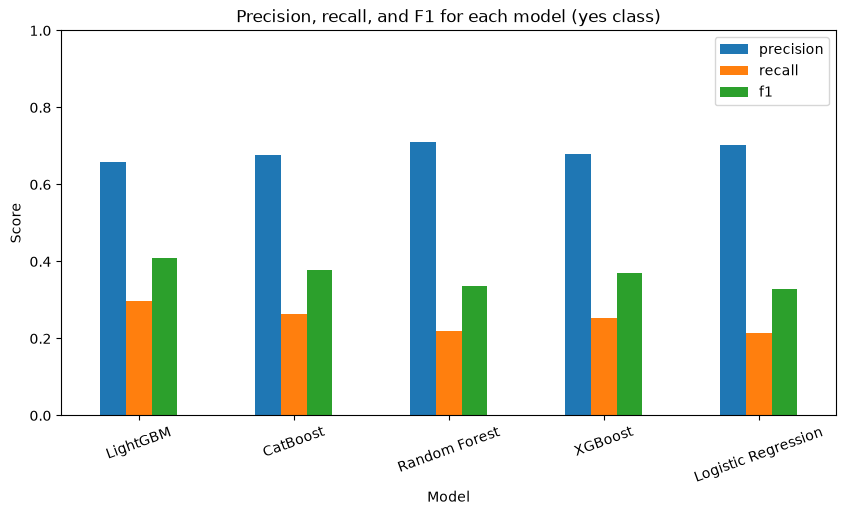

In [29]:
# a grouped bar chart of precision, recall, and f1 for each model
comparison[["precision", "recall", "f1"]].plot(kind="bar", figsize=(10, 5))
plt.title("Precision, recall, and F1 for each model (yes class)")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="upper right")
plt.show()


The bar chart makes the imbalance problem easy to see. For every model the recall bar is
much shorter than the precision bar. In plain words: when a model does say yes it is often
right (decent precision), but it stays silent on many real subscribers (low recall). If the
business goal is to catch more subscribers, this is the number we would work to raise.


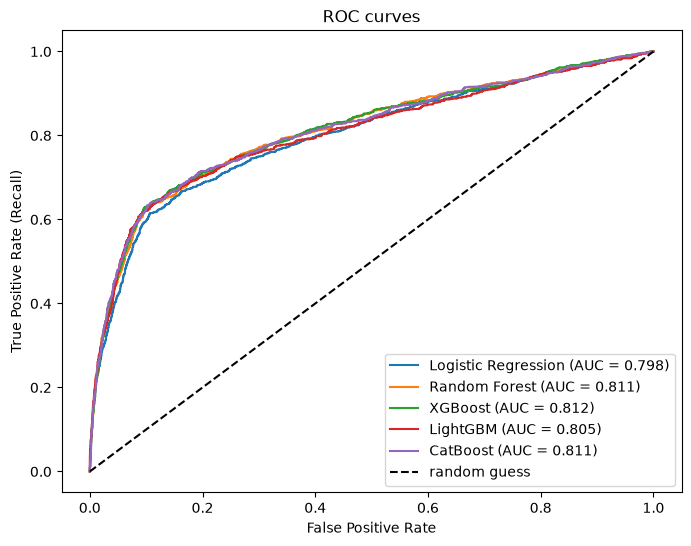

In [30]:
# ROC curves for all models on the same plot
plt.figure(figsize=(8, 6))
for model_name in model_scores:
    fpr, tpr, thresholds = roc_curve(y_test, model_scores[model_name])
    auc_value = results[model_name]["roc_auc"]
    plt.plot(fpr, tpr, label=model_name + " (AUC = " + str(round(auc_value, 3)) + ")")

# the diagonal line is a model that guesses at random
plt.plot([0, 1], [0, 1], "k--", label="random guess")
plt.title("ROC curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.show()


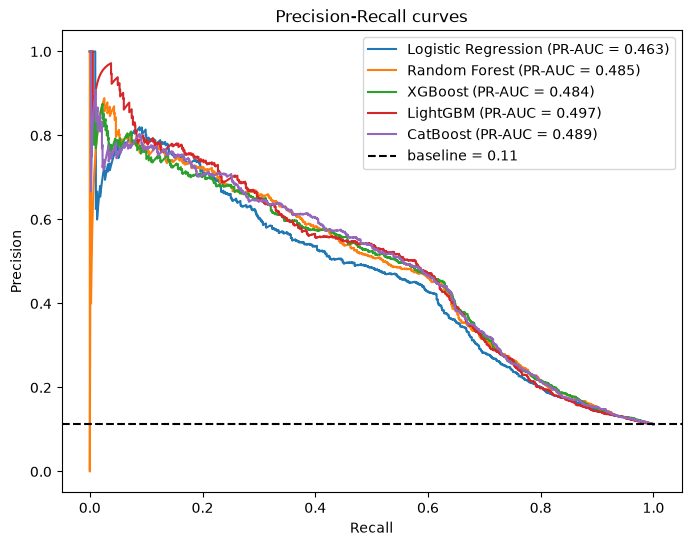

In [31]:
# Precision-Recall curves for all models on the same plot
plt.figure(figsize=(8, 6))
for model_name in model_scores:
    precision_values, recall_values, thresholds = precision_recall_curve(y_test, model_scores[model_name])
    ap_value = results[model_name]["pr_auc"]
    plt.plot(recall_values, precision_values, label=model_name + " (PR-AUC = " + str(round(ap_value, 3)) + ")")

# the flat dashed line is the baseline, equal to the share of yes customers
baseline = y_test.mean()
plt.axhline(baseline, linestyle="--", color="k", label="baseline = " + str(round(baseline, 2)))
plt.title("Precision-Recall curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="upper right")
plt.show()


### Reading the curves (intuition)

- In the ROC plot every model hugs the top-left corner and the curves sit well above the
  diagonal. This looks impressive, but remember the False Positive Rate on the x-axis is
  measured against the very large no group, so it is easy to keep it small. ROC is useful for
  ranking and comparing, but it is a gentle judge here.
- In the Precision-Recall plot the curves start high and then fall as we ask for more recall.
  The dashed baseline is at about 0.11, the share of yes customers. A random model would sit on
  that line, so any curve above it is adding value. The area under each curve (the PR-AUC in
  the legend) is a much stricter and more honest score for this problem than the ROC-AUC.
- The practical reading: to reach high recall (catch most subscribers), precision drops, which
  means more wasted calls. The right operating point on this curve is a business decision, and
  it depends on how many calls the team can afford to make.


## Step 11: Boosting recall (catching more of the yes customers)

The metrics above showed a real problem: recall is low, around 0.2 to 0.3, so the models miss
most of the customers who would actually subscribe. Let us understand why, and then fix it.

Recall is low for two reasons:

1. The data is imbalanced. Only about 11 percent of customers say yes. When a model tries to
   be correct overall, the safe bet is to lean towards no, because no is almost always right.
   The model is barely punished for missing a yes, so it does not try hard to catch them.
2. The default decision rule is strict. A model says yes only when it thinks the chance of yes
   is above 0.5. But because yes is rare, the predicted chance is usually low and rarely crosses
   0.5, so many real yes customers are labelled no.

We will fix each cause with one lever.


### Lever 1: tell the models that the classes matter equally (class weights)

Every model has a setting that makes a mistake on the rare class count for more. This pushes
the model to pay attention to the yes customers. The setting has a different name in each
library:

- Logistic Regression and Random Forest: class_weight = "balanced"
- XGBoost: scale_pos_weight = (number of no) / (number of yes)
- LightGBM: class_weight = "balanced"
- CatBoost: auto_class_weights = "Balanced"

We train each model again with this setting turned on, and measure the same metrics.


In [ ]:
scale_pos_weight = 89/11 = 8.1 #(11 yes, 89 no) 
cost = summation (loss of ith sample * weight of ith sample)

In [32]:
# for XGBoost we need the ratio of no to yes in the training data
number_of_yes = (y_train == 1).sum()
number_of_no = (y_train == 0).sum()
scale_pos_weight = number_of_no / number_of_yes
print("For every yes there are about", round(scale_pos_weight, 1), "no customers in training")

# a place to store the results of the balanced models
results_balanced = {}

def fit_balanced(model, model_name, X_tr, X_te, fit_params=None):
    if fit_params is None:
        fit_params = {}

    model.fit(X_tr, y_train, **fit_params)
    predictions = model.predict(X_te)

    metrics = {
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions),
        "f1": f1_score(y_test, predictions),
    }
    results_balanced[model_name] = metrics
    print(model_name,
          "-> recall:", round(metrics["recall"], 3),
          " precision:", round(metrics["precision"], 3),
          " f1:", round(metrics["f1"], 3))
    return model


For every yes there are about 7.9 no customers in training


In [33]:
# Logistic Regression and Random Forest use Version A (one-hot)
fit_balanced(
    LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Logistic Regression", X_enc_train, X_enc_test)

fit_balanced(
    RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42,
                           class_weight="balanced"),
    "Random Forest", X_enc_train, X_enc_test)

# XGBoost, LightGBM, CatBoost use Version B (categories kept)
fit_balanced(
    XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, random_state=42,
                  eval_metric="logloss", enable_categorical=True, tree_method="hist",
                  scale_pos_weight=scale_pos_weight),
    "XGBoost", X_nat_train, X_nat_test)

fit_balanced(
    LGBMClassifier(n_estimators=200, num_leaves=31, learning_rate=0.1, random_state=42,
                   verbose=-1, class_weight="balanced"),
    "LightGBM", X_nat_train, X_nat_test)

fit_balanced(
    CatBoostClassifier(n_estimators=200, depth=4, learning_rate=0.1, random_state=42,
                       verbose=0, auto_class_weights="Balanced"),
    "CatBoost", X_nat_train, X_nat_test,
    fit_params={"cat_features": categorical_columns})


Logistic Regression -> recall: 0.649  precision: 0.356  f1: 0.46
Random Forest -> recall: 0.636  precision: 0.409  f1: 0.498
XGBoost -> recall: 0.656  precision: 0.385  f1: 0.485
LightGBM -> recall: 0.638  precision: 0.399  f1: 0.491
CatBoost -> recall: 0.655  precision: 0.38  f1: 0.481


CatBoostClassifier(auto_class_weights='Balanced', depth=4, learning_rate=0.1, n_estimators=200, random_state=42, verbose=0)

In [34]:
# compare recall before (default models) and after (balanced models)
recall_before = {}
recall_after = {}
for model_name in results:
    recall_before[model_name] = results[model_name]["recall"]
    recall_after[model_name] = results_balanced[model_name]["recall"]

recall_comparison = pd.DataFrame({
    "before (default)": recall_before,
    "after (balanced)": recall_after,
})
recall_comparison = recall_comparison.round(3)
recall_comparison


,before (default),after (balanced)
Logistic Regression,0.213,0.649
Random Forest,0.220,0.636
XGBoost,0.254,0.656
LightGBM,0.296,0.638
CatBoost,0.263,0.655


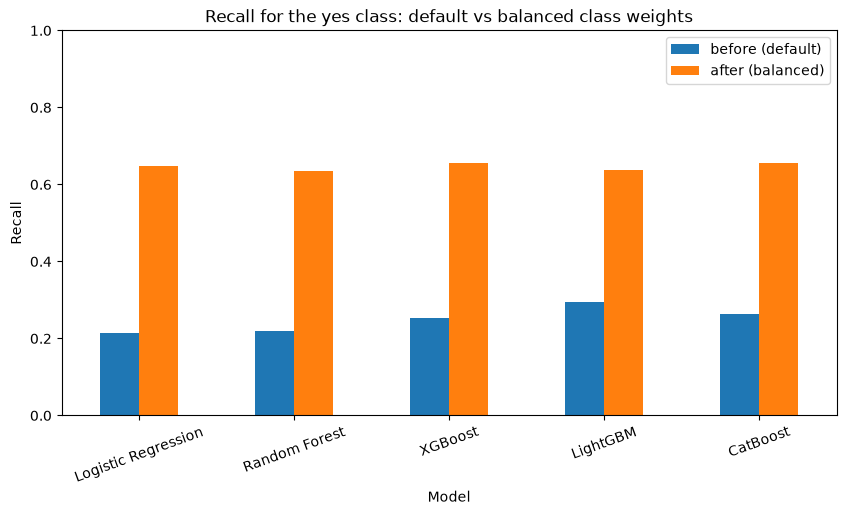

In [35]:
# show the same comparison as a bar chart
recall_comparison.plot(kind="bar", figsize=(10, 5))
plt.title("Recall for the yes class: default vs balanced class weights")
plt.xlabel("Model")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="upper right")
plt.show()


Intuition. Recall jumps up a lot, from around 0.2 to 0.3 up to around 0.65. The models now
catch about two thirds of the real subscribers instead of a quarter. In return, precision goes
down (more of the flagged customers turn out to be no) and the plain accuracy also drops. That
is the expected trade, and it is fine, because for this campaign catching subscribers is worth
more than a high accuracy number.


### Lever 2: lower the decision threshold

The second lever does not even need retraining. We take a model we already trained and simply
change the cutoff. Instead of saying yes only when the chance is above 0.5, we can say yes when
the chance is above, say, 0.2. This catches more real subscribers.

We reuse the yes-probabilities from the tuned LightGBM (which we saved earlier in model_scores)
and try a range of cutoffs.


In [36]:
# the yes-probabilities from the tuned LightGBM, saved back in Step 9
probabilities = model_scores["LightGBM"]

# try several cutoffs and record precision, recall, and f1 for each
rows = []
for threshold in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1]:
    predictions = (probabilities >= threshold).astype(int)
    rows.append({
        "threshold": threshold,
        "precision": round(precision_score(y_test, predictions), 3),
        "recall": round(recall_score(y_test, predictions), 3),
        "f1": round(f1_score(y_test, predictions), 3),
    })

threshold_table = pd.DataFrame(rows)
threshold_table


,threshold,precision,recall,f1
0,0.50,0.659,0.296,0.409
1,0.40,0.572,0.376,0.454
2,0.30,0.530,0.513,0.521
3,0.20,0.472,0.600,0.528
4,0.15,0.427,0.630,0.509
5,0.10,0.334,0.684,0.449


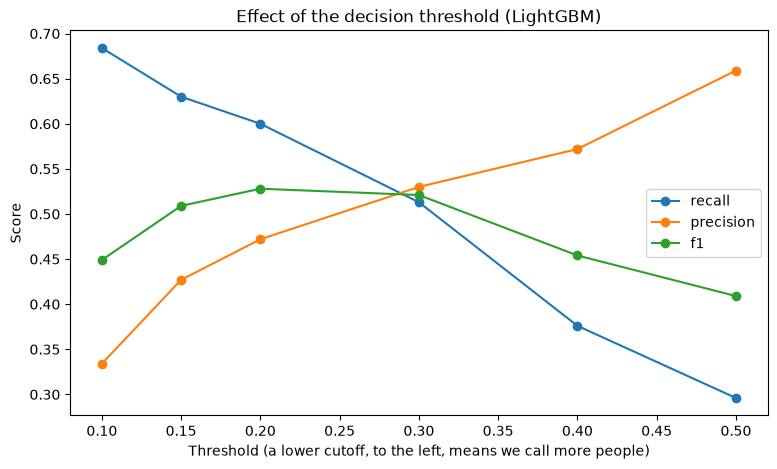

In [37]:
# plot how precision, recall, and f1 change with the threshold
plt.figure(figsize=(9, 5))
plt.plot(threshold_table["threshold"], threshold_table["recall"], marker="o", label="recall")
plt.plot(threshold_table["threshold"], threshold_table["precision"], marker="o", label="precision")
plt.plot(threshold_table["threshold"], threshold_table["f1"], marker="o", label="f1")
plt.title("Effect of the decision threshold (LightGBM)")
plt.xlabel("Threshold (a lower cutoff, to the left, means we call more people)")
plt.ylabel("Score")
plt.legend()
plt.show()


In [38]:
# suppose the business wants to catch most subscribers, so we pick a lower cutoff
chosen_threshold = 0.2
final_predictions = (probabilities >= chosen_threshold).astype(int)

print("Using threshold =", chosen_threshold)
print("Recall:", round(recall_score(y_test, final_predictions), 3))
print("Precision:", round(precision_score(y_test, final_predictions), 3))
print("F1:", round(f1_score(y_test, final_predictions), 3))
print()
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, final_predictions))


Using threshold = 0.2
Recall: 0.6
Precision: 0.472
F1: 0.528

Confusion matrix (rows = actual, columns = predicted):
[[6686  624]
 [ 371  557]]


Intuition. As we lower the threshold from 0.5 down to 0.1, recall climbs steadily while
precision falls. The f1 score is highest somewhere in the middle (around 0.2 to 0.3), which is
a balanced choice. There is no single correct threshold: it is a business decision. If calls
are cheap and missing a subscriber is costly, pick a low threshold for high recall. If each
call is expensive, keep the threshold higher to protect precision.

Both levers do the same basic thing in different ways: they trade some precision to gain a lot
of recall. Which balance is right depends on the cost of a call versus the value of a new
subscriber.


## What we learned, and my intuitions

Main lessons from this notebook:

- Different models want their input in different shapes. Logistic Regression and Random Forest
  needed numbers, so we used one-hot encoding (Version A). XGBoost, LightGBM, and CatBoost can
  read categorical columns directly, so we gave them the raw columns (Version B). Keeping two
  versions of the data let every model use its favourite style.
- One-hot encoding creates many extra columns (62 here), while the native approach keeps the
  table small (19 here). For data with many categories, the native approach can be simpler and
  faster while reaching the same quality.
- A little hyperparameter tuning with GridSearchCV helps each model find better settings, and
  we tuned on PR-AUC, not accuracy, so the tuning aimed at the goal we actually care about.

My intuitions about the metrics, in plain words:

- Accuracy is the wrong headline here. With about 89 percent of customers saying no, a lazy
  model that always says no already scores about 0.89. When every model lands near 0.90, that
  is barely above doing nothing, so accuracy cannot tell the models apart or tell us if they
  are useful.
- Recall is the number that exposes the real difficulty. It is low, which means the models are
  missing many real subscribers. This is completely hidden if we only look at accuracy.
- ROC-AUC looks high and reassuring, but it is a gentle judge on imbalanced data because its
  False Positive Rate is measured against the huge no group. It is good for ranking and for
  comparing across datasets, but it flatters the models here.
- PR-AUC is the honest headline. It only looks at the rare yes class, its baseline is about
  0.11 (the share of yes), and it drops as soon as a model wastes calls on non-subscribers. If
  I had to pick one number to report to the business, it would be this one.
- The precision-recall curve is not just a score, it is a menu. Each point is a possible cutoff
  with its own trade-off between catching subscribers (recall) and wasting calls (precision).
  Picking the point is a business decision that depends on the calling budget, not something
  the model decides for us.

Things you can try next:

- Raise recall on purpose, for example with class_weight="balanced" or scale_pos_weight, and
  watch precision fall in return. This makes the trade-off very concrete.
- Instead of the default 0.5 cutoff, choose the threshold from the precision-recall curve that
  matches your calling budget (for example, the point that gives the best recall while keeping
  precision above some level).
- Make the tuning grids larger, or try RandomizedSearchCV, and see if the scores improve.
